# 06 - MLCC on the 14 French cities (Section VII)

Computes the % of achievable safety / comfort for the 10 budgets $\alpha_i$ (Fig. 12) and draws Grenoble upgraded with MLCC for $\alpha_7$ (Fig. 10). MLCC is deterministic. Runtime: about 1 hour the first time (Paris alone takes ~25 min), then cached.

**Choose the model variant** (see README, section *Two model variants*):

* `"dos"` (default) - integer DoS weights, linear models in $s_\mathcal{G}$ and $l_\mathcal{G}$ (ITSC-2024 calibration), exponential cost per metre.
* `"cscs"` - CycleRAP/CSCS weights, NNLS model $\tilde\theta=[0.41, 0.58, 0.45, 0.57]$ of Eq. (10), Cerema costs.
  With this model safety and comfort percentages are identical, because the prediction only depends on $l_\mathcal{G}$.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # the cycling_tits package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from cycling_tits import CITIES, FIGURES, RESULTS, load_network, load_survey, pretty, Model, alphas
FIGURES.mkdir(exist_ok=True)

In [2]:
from cycling_tits.optimizers import run_mlcc, evaluate
from cycling_tits.plotting import fourteen_cities, city_map
from tqdm.auto import tqdm

PRESET = "dos"           # or "cscs"
OUT = FIGURES / PRESET; OUT.mkdir(exist_ok=True)
cache = RESULTS / PRESET / "fourteen_cities_mlcc.json"
cache.parent.mkdir(parents=True, exist_ok=True)

# MLCC only depends on the costs, not on the safety/comfort model, so it is run once per
# city and budget and both models are evaluated on the same upgrade plan.
if cache.exists():
    res = json.load(open(cache))
else:
    models = {t: Model(PRESET, t) for t in ["safety", "comfort"]}
    res = {t: {} for t in models}
    for city in tqdm(CITIES):
        G = load_network(city)
        runs = [run_mlcc(models["safety"], G, a) for a in alphas()]
        for t, model in models.items():
            y0 = model.predict(G)
            ys = [evaluate(model, G, r["levels"]) if t != "safety" else r["y"] for r in runs]
            res[t][city] = {"y0": y0, "y": ys, "percent": [model.percent(y, y0) for y in ys],
                            "time_s": [r["time_s"] for r in runs], "levels_alpha7": runs[7]["levels"]}
    json.dump(res, open(cache, "w"))

C:\Users\Administrator\anaconda3\envs\cycling-tits\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
pct = {t: pd.DataFrame({pretty(c): res[t][c]["percent"] for c in CITIES}, index=[f"i={i}" for i in range(10)]).T.round(2)
       for t in ["safety", "comfort"]}
pct["safety"]

,i=0,i=1,i=2,i=3,i=4,i=5,i=6,i=7,i=8,i=9
Angers,0.95,2.84,3.93,6.18,9.32,13.86,20.91,32.01,48.81,100.0
Annecy,1.40,2.30,4.45,6.63,10.92,17.03,27.31,43.82,80.43,100.0
Bordeaux,0.05,1.97,2.78,7.33,11.34,15.85,22.83,33.92,49.73,100.0
Chambery,3.59,4.17,5.30,7.33,10.55,15.53,24.07,36.07,59.64,100.0
Dunkerque,0.55,0.97,2.29,7.17,9.93,15.57,24.33,35.06,52.15,100.0
Grenoble,1.56,2.23,3.73,6.35,9.88,16.65,26.84,41.99,64.83,100.0
La Rochelle,3.63,4.34,5.39,7.03,9.77,15.12,22.05,31.62,48.27,100.0
Le Havre,4.20,7.81,12.44,16.46,24.41,29.52,37.60,50.91,94.25,100.0
Lyon,2.49,3.33,4.63,6.90,10.50,16.16,25.80,39.73,63.01,100.0
Nantes,1.29,1.91,3.15,4.97,8.27,13.50,21.20,32.60,51.45,100.0


## Fig. 12 - safety (top) and comfort (bottom)

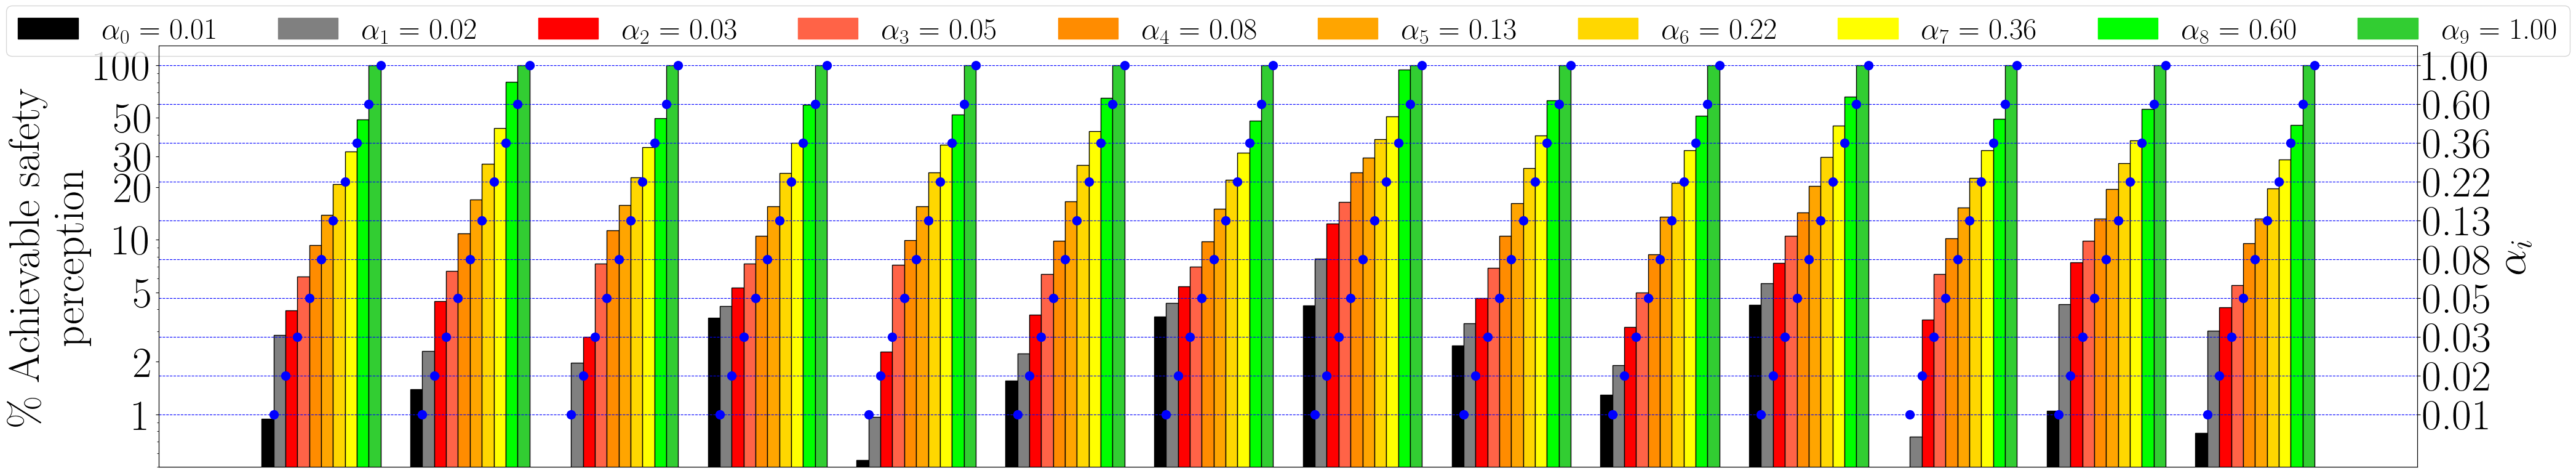

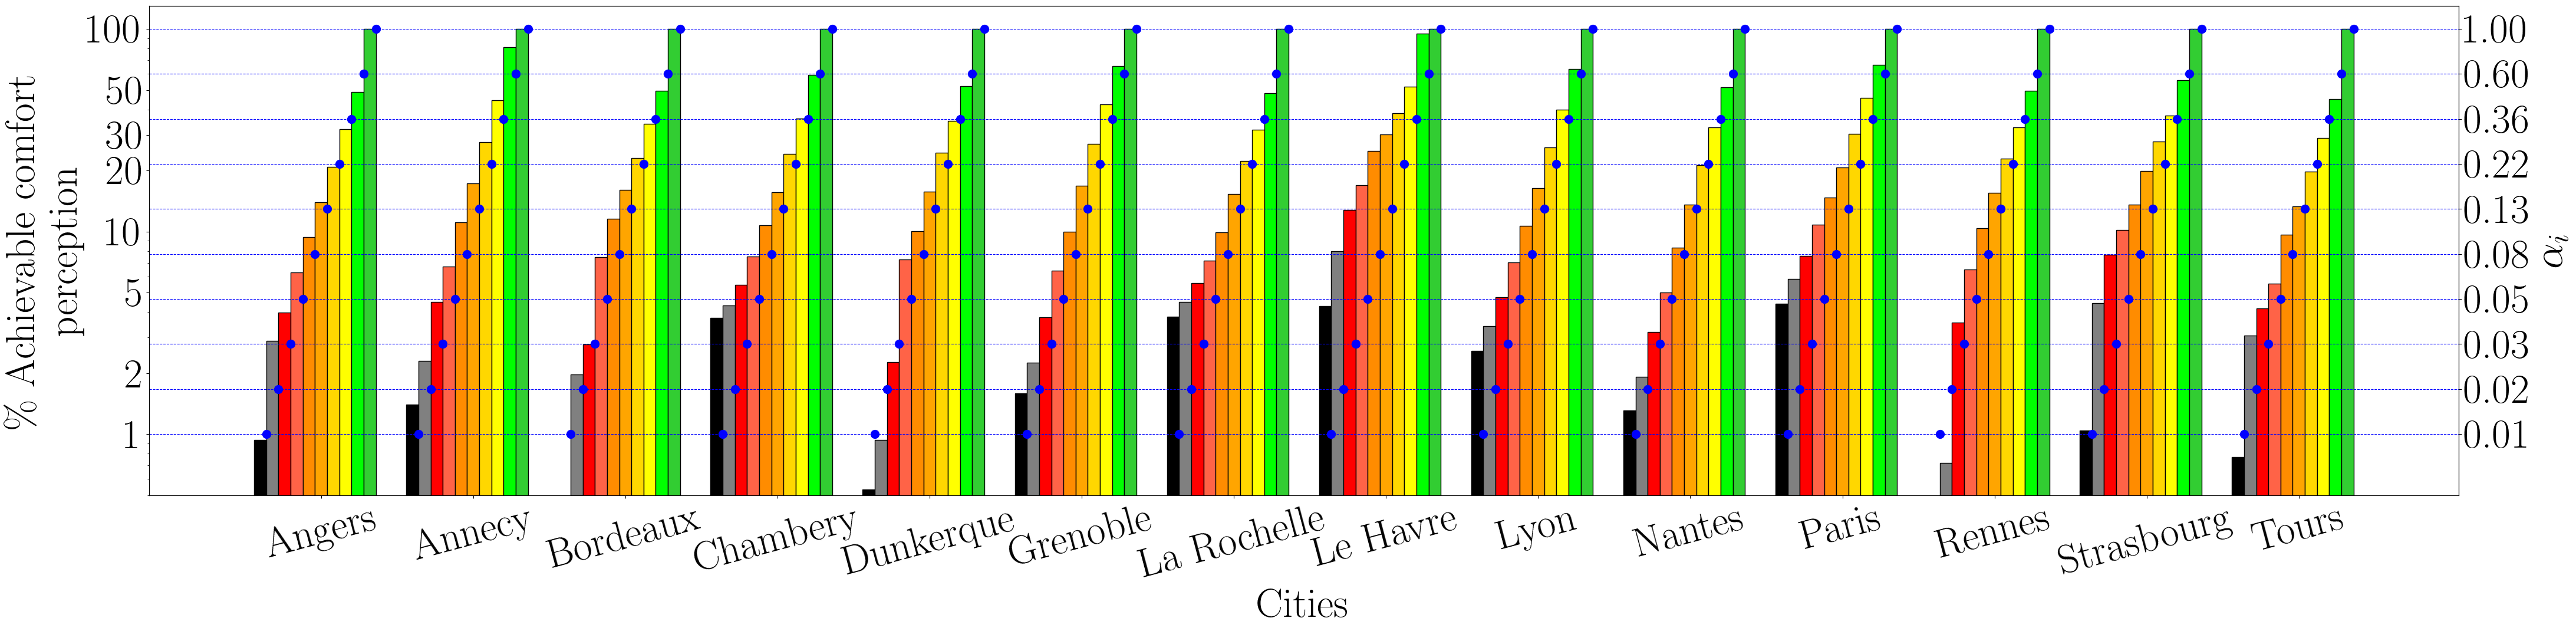

In [4]:
fourteen_cities({c: res["safety"][c]["percent"] for c in CITIES}, "safety",
                outfile=OUT / "maximize_safety_fourteen.png", show_cities=False)
fourteen_cities({c: res["comfort"][c]["percent"] for c in CITIES}, "comfort",
                outfile=OUT / "maximize_comfort_fourteen.png", show_legend=False);

## Fig. 10 - Grenoble upgraded by MLCC for safety with $\alpha_7 \approx 0.36$ (upgraded links drawn thicker)

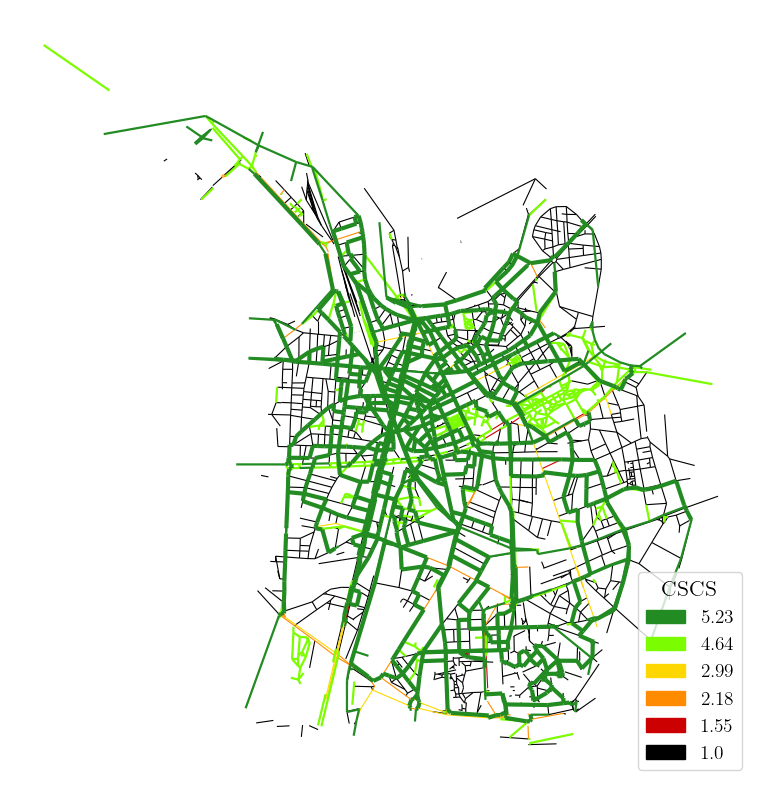

In [5]:
G = load_network("Grenoble")
city_map(G, res["safety"]["Grenoble"]["levels_alpha7"], highlight_changes=True,
         outfile=OUT / "Map_and_scale_changes.png");